# Etapa 8. Grafo de dominio (Grafo de co-compra, PageRank y Detección de Comunidades)

Proyecto EDA 2026-2 · Grupo 1 · Escenario B (comercio electrónico)

Esta etapa modela la red de relaciones de co-compra entre los productos del catálogo de Amazon Reviews 2023 (`Office_Products`). Construye un grafo no dirigido y ponderado en representación **CSR** (*Compressed Sparse Row*) a partir de las órdenes multiactivo del stream procesado en la etapa 2, aplicando un filtro estricto sobre las 31 994 órdenes marcadas como fraudulentas en la etapa 6. Sobre esta topología, se implementan y evalúan dos familias algorítmicas de análisis de grafos:

1. **Centralidad e influencia espectral:** **PageRank** con iteración de potencias vectorizada (*Power Iteration* con SpMV sobre CSR) frente a la línea base de **Grado Ponderado**.
2. **Detección de estructuras de comunidad:** **Algoritmo de Louvain multinivel** optimizando la modularidad de Newman-Girvan frente a la línea base de **Label Propagation Algorithm (LPA)**.

Adicionalmente, se contrastan ambas implementaciones frente a la biblioteca estándar abierta **NetworkX** en tiempo de ejecución, memoria pico (`tracemalloc`) y calidad métrica.


## Paso 1. Configuración y entrada

Se definen las rutas canónicas del proyecto, la semilla determinista (`SEED = 42`), la detección de plataforma y el protocolo de reutilización de experimentos mediante `resultados()`.


In [1]:
import gc
import json
import os
import platform
import sys
import time
import tracemalloc
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

# Asegurar raíz del proyecto en sys.path
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
    os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.etapa_3.storage import AlmacenCatalogo
from src.etapa_8.graph import (
    GrafoCoCompra,
    componentes_conexas,
    dividir_comunidades_desconectadas,
    extraer_cocompras,
    grado_ponderado_ranking,
    label_propagation,
    louvain,
    modularidad,
    ordenes_bloqueadas,
    pagerank,
)

# Rutas del pipeline
CATEGORIA = "Office_Products"
DIR_INTERIM = RAIZ / "data" / "interim" / CATEGORIA
RUTA_EVENTOS = DIR_INTERIM / "etapa2_eventos.jsonl"
RUTA_BLOQUEADOS = DIR_INTERIM / "etapa_6" / "ordenes_bloqueadas.json"
RUTA_CATALOGO = DIR_INTERIM / "etapa_3" / "catalogo.jsonl"

DIR_ETAPA8 = DIR_INTERIM / "etapa_8"
DIR_ETAPA8.mkdir(parents=True, exist_ok=True)
RUTA_GRAFO = DIR_ETAPA8 / "grafo_cocompra.npz"
RUTA_PAGERANK = DIR_ETAPA8 / "pagerank.parquet"
RUTA_COMUNIDADES = DIR_ETAPA8 / "comunidades.parquet"
RUTA_METRICAS = DIR_ETAPA8 / "metricas.json"

DIR_RESULTADOS = RAIZ / "results" / "etapa_8"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

SEED = 42
PLATAFORMA = {
    "procesador": platform.processor() or platform.machine(),
    "python": platform.python_version(),
    "sistema": platform.system(),
}
print("Entorno configurado:", PLATAFORMA)


Entorno configurado: {'procesador': 'arm', 'python': '3.12.13', 'sistema': 'Darwin'}


In [2]:
# Protocolo de persistencia y reutilización de mediciones
REEJECUTAR_EXPERIMENTOS = False
R = DIR_RESULTADOS


def resultados(ruta, medir_tabla, requeridas=()):
    """Lee la tabla de resultados si existe. Si no, ejecuta la medición y la guarda."""
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        tabla = pd.read_csv(ruta)
        if all(c in tabla.columns for c in requeridas):
            print(f"Resultados leídos de {ruta.name}")
            return tabla
    tabla = medir_tabla().assign(procesador=PLATAFORMA["procesador"], python=PLATAFORMA["python"])
    tabla.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta.name}")
    return tabla


def plataforma_de(tabla):
    if "procesador" in tabla.columns and "python" in tabla.columns:
        return f"{tabla['procesador'].iloc[0]}, Python {tabla['python'].iloc[0]}"
    return f"{PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}"


def medir(funcion, *args):
    """Mide segundos con GC pausado."""
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        resultado = funcion(*args)
        segundos = time.perf_counter() - t0
    finally:
        gc.enable()
    return segundos, resultado


def medir_memoria(funcion, *args):
    """Mide resultado, memoria actual y memoria pico en bytes con tracemalloc."""
    gc.collect()
    tracemalloc.start()
    resultado = funcion(*args)
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return resultado, actual, pico


## Paso 2. Grafo de co-compra y topología

El grafo de co-compra $G = (V, E, W)$ modela la interacción de canasta de mercado (*market basket analysis*):
- Los vértices $V$ corresponden a los productos (identificados unívocamente por su `parent_asin`).
- Una arista $(u, v) \in E$ con peso $w_{uv} \in \mathbb{N}_{\ge 1}$ indica que los productos $u$ y $v$ fueron adquiridos juntos en $w_{uv}$ órdenes de compra distintas.
- **Exclusión de fraude (Etapa 6):** Para blindar el grafo contra ataques de envenenamiento (*graph poisoning*) y co-ocurrencias anómalas, se consultan las alertas de la etapa 6 y se excluyen todas las transacciones pertenecientes a órdenes bloqueadas.
- **Representación en memoria (CSR):** Se almacena el grafo como matriz dispersa simétrica con punteros de fila `indptr`, columnas adyacentes `indices` y pesos de aristas `data`, logrando una complejidad de almacenamiento $O(|V| + |E|)$ sin sobrecarga de punteros de objetos de Python.


In [3]:
# 2.1 Carga o extracción del grafo de co-compra
if RUTA_GRAFO.exists():
    print("Cargando grafo precomputado desde:", RUTA_GRAFO)
    grafo = GrafoCoCompra.cargar_npz(RUTA_GRAFO)
else:
    print("Extrayendo grafo desde el stream de eventos...")
    bloqueadas = ordenes_bloqueadas(RUTA_BLOQUEADOS)
    grafo, ordenes_totales, compras_totales, descartadas = extraer_cocompras(
        RUTA_EVENTOS, bloqueadas
    )
    grafo.guardar_npz(RUTA_GRAFO)

n = grafo.n
m_aristas = grafo.m
w_total = grafo.peso_total
grados = grafo.grados
grados_ponderados = grafo.grados_ponderados()

print(f"Vértices (|V|): {n:,}")
print(f"Aristas no dirigidas (|E|): {m_aristas:,}")
print(f"Entradas no nulas en CSR: {len(grafo.indices):,}")
print(f"Suma total de pesos (2m): {w_total:,.1f}")
print(f"Grado promedio: {np.mean(grados):.2f}")
print(f"Grado máximo: {np.max(grados):,} (ponderado: {np.max(grados_ponderados):,})")
print(f"Densidad de la red: {2 * m_aristas / (n * (n - 1)):.8f}")


Cargando grafo precomputado desde: /Users/jesus/Documents/Maestria/Estructura_datos_algortmos/tarea/Compras/proyecto_final_grupo1-main/data/interim/Office_Products/etapa_8/grafo_cocompra.npz
Vértices (|V|): 150,534
Aristas no dirigidas (|E|): 805,587
Entradas no nulas en CSR: 1,611,174
Suma total de pesos (2m): 1,067,474.0
Grado promedio: 10.70
Grado máximo: 279 (ponderado: 1,606.0)
Densidad de la red: 0.00007110


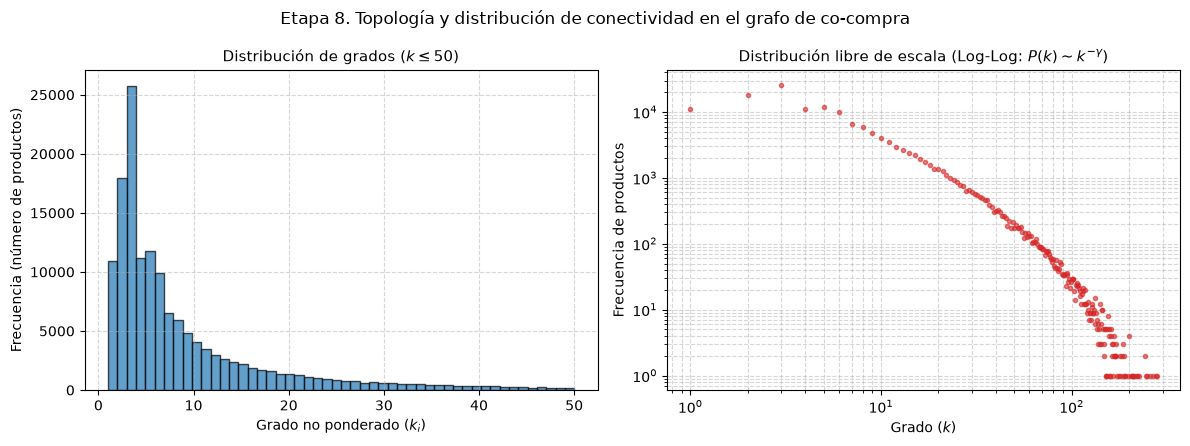

In [4]:
# 2.2 Distribución de Grados (Scale-free network)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histograma de grados (escala lineal con límite)
axes[0].hist(grados[grados <= 50], bins=50, color="#1f77b4", edgecolor="black", alpha=0.7)
axes[0].set_title(r"Distribución de grados ($k \leq 50$)", fontsize=11)
axes[0].set_xlabel("Grado no ponderado ($k_i$)", fontsize=10)
axes[0].set_ylabel("Frecuencia (número de productos)", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Distribución log-log acumulada
grados_pos = grados[grados > 0]
k_vals, counts = np.unique(grados_pos, return_counts=True)
axes[1].loglog(k_vals, counts, "o", color="#d62728", markersize=3, alpha=0.6)
axes[1].set_title(r"Distribución libre de escala (Log-Log: $P(k) \sim k^{-\gamma}$)", fontsize=11)
axes[1].set_xlabel("Grado ($k$)", fontsize=10)
axes[1].set_ylabel("Frecuencia de productos", fontsize=10)
axes[1].grid(True, which="both", linestyle="--", alpha=0.5)

fig.suptitle("Etapa 8. Topología y distribución de conectividad en el grafo de co-compra", fontsize=12)
fig.tight_layout()
plt.show()


## Paso 3. Centralidad e influencia: PageRank

El algoritmo **PageRank** (Brin & Page, 1998) modela un paseo aleatorio con reinicio sobre la red de co-compras:
- Con probabilidad $\alpha$ (factor de amortiguamiento, típicamente $0.85$), el navegante sigue una arista proporcional al peso de co-compra $P_{ij} = \frac{w_{ij}}{k_i}$.
- Con probabilidad $1 - \alpha$, salta uniformemente a cualquier nodo de la red.
- Los nodos colgantes (*dangling nodes*, con $k_i = 0$) redistribuyen su masa de probabilidad equitativamente entre todos los nodos:
  $$p_{t+1} = \alpha P^T p_t + \left( \alpha \frac{\sum_{j \in \text{Dangling}} p_t(j)}{n} + \frac{1 - \alpha}{n} \right) \mathbf{1}$$

La multiplicación matriz-vector dispersa (SpMV) se resuelve de forma vectorizada en $O(|E|)$ mediante `np.bincount`, garantizando una convergencia geométrica $\|p_{t+1} - p_t\|_1 < \epsilon$ en pocas iteraciones.


In [5]:
# 3.1 Ejecución de PageRank vs Grado Ponderado
ALPHA = 0.85
TOL = 1e-6
MAX_ITER = 100

t0 = time.perf_counter()
pr_scores, iter_pr, conv_pr = pagerank(grafo, alpha=ALPHA, tol=TOL, max_iter=MAX_ITER)
t_pr = time.perf_counter() - t0

t0 = time.perf_counter()
grado_scores = grado_ponderado_ranking(grafo)
t_grado = time.perf_counter() - t0

print(f"PageRank converged: {conv_pr} in {iter_pr} iteraciones ({t_pr*1000:.2f} ms)")
print(f"Grado Ponderado computed in: {t_grado*1000:.2f} ms")
print(f"Suma de PageRank: {np.sum(pr_scores):.6f} (normalizado)")
print(f"Top 1 PageRank Score: {np.max(pr_scores):.6f}")


PageRank converged: True in 25 iteraciones (204.21 ms)
Grado Ponderado computed in: 0.08 ms
Suma de PageRank: 1.000000 (normalizado)
Top 1 PageRank Score: 0.000396


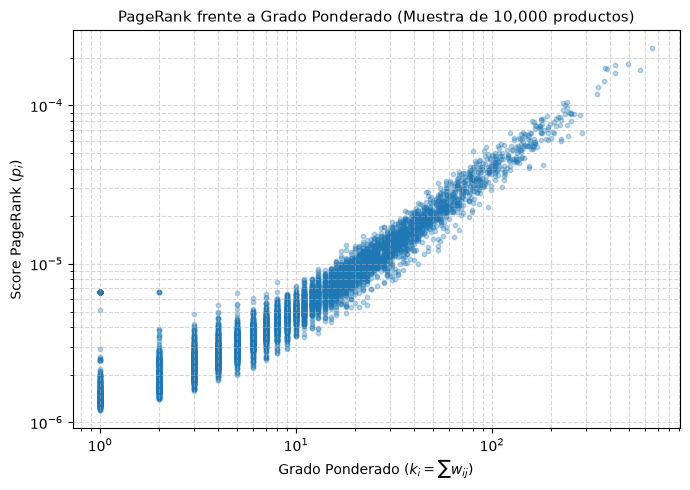

In [6]:
# 3.2 Correlación y contraste: PageRank vs Grado Ponderado
idx_sample = np.random.default_rng(SEED).choice(n, size=min(10_000, n), replace=False)

plt.figure(figsize=(7, 5))
plt.scatter(grados_ponderados[idx_sample], pr_scores[idx_sample], alpha=0.3, s=10, c="#1f77b4")
plt.xscale("log")
plt.yscale("log")
plt.title(f"PageRank frente a Grado Ponderado (Muestra de {len(idx_sample):,} productos)", fontsize=11)
plt.xlabel(r"Grado Ponderado ($k_i = \sum w_{ij}$)", fontsize=10)
plt.ylabel("Score PageRank ($p_i$)", fontsize=10)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## Paso 4. Detección de comunidades: Algoritmo de Louvain

El algoritmo de **Louvain** (Blondel et al., 2008) busca una partición $\mathcal{C} = \{C_1, C_2, \dots, C_k\}$ de los productos que maximice la **modularidad de Newman-Girvan** (Newman, 2006):
$$Q = \frac{1}{2m} \sum_{ij} \left( A_{ij} - \gamma \frac{k_i k_j}{2m} \right) \delta(c_i, c_j)$$

donde $2m = \sum_{ij} A_{ij}$, $k_i = \sum_j A_{ij}$, y $\gamma$ es el parámetro de resolución.

Louvain opera en dos fases iterativas:
1. **Fase 1 (Optimización codiciosa local):** Cada nodo se traslada a la comunidad vecina que maximice la ganancia local de modularidad:
   $$\Delta Q = \frac{k_{i, in}}{2m} - \gamma \frac{k_i \Sigma_{tot}}{2m^2}$$
   donde $k_{i, in}$ es el peso de las aristas de $i$ hacia la comunidad objetivo, y $\Sigma_{tot}$ es la suma de los grados de dicha comunidad.
2. **Fase 2 (Contracción multinivel):** Las comunidades identificadas se agrupan en super-vértices, sumando los enlaces internos como bucles propios (*self-loops*) y los enlaces externos como aristas ponderadas entre super-vértices.

El proceso se repite jerárquicamente hasta que ninguna reasignación incremente la modularidad más allá de un umbral $\Delta Q < 10^{-7}$.


In [7]:
# 4.1 Ejecución de Louvain multinivel
t0 = time.perf_counter()
comunidades_louvain, mod_louvain, niveles_louvain = louvain(grafo, resolucion=1.0, max_niveles=10, semilla=SEED)
t_louvain = time.perf_counter() - t0

conteo_louvain = pd.Series(comunidades_louvain).value_counts()

print(f"Louvain finalizado en {t_louvain:.2f} s")
print(f"Niveles jerárquicos alcanzados: {niveles_louvain}")
print(f"Modularidad Newman-Girvan (Q): {mod_louvain:.6f}")
print(f"Número de comunidades detectadas: {len(conteo_louvain):,}")
print(f"Tamaño comunidad más grande: {conteo_louvain.iloc[0]:,} productos")
print(f"Mediana de tamaño de comunidad: {conteo_louvain.median():.1f} productos")


Louvain finalizado en 4.01 s
Niveles jerárquicos alcanzados: 3
Modularidad Newman-Girvan (Q): 0.997920
Número de comunidades detectadas: 841
Tamaño comunidad más grande: 356 productos
Mediana de tamaño de comunidad: 282.0 productos


## Paso 5. Línea base: Label Propagation Algorithm (LPA)

Como contraste algorítmico, implementamos el algoritmo de propagación de etiquetas (**LPA**, Raghavan et al., 2007):
- Cada nodo inicia con su propia etiqueta identificadora.
- En cada iteración asíncrona, los nodos se visitan en orden aleatorio y adoptan la etiqueta que acumule el mayor peso total entre sus vecinos:
  $$c_i \leftarrow \arg\max_c \sum_{j \in N(i), c_j = c} w_{ij}$$
- LPA es extremadamente rápido ($O(|E|)$ por ronda) y no requiere optimizar una función objetivo global, pero puede sufrir de oscilaciones y formación de componentes dominantes gigantes sin resolución ajustable.


In [8]:
# 5.1 Ejecución de LPA
t0 = time.perf_counter()
comunidades_lpa, iter_lpa, mod_lpa = label_propagation(grafo, max_iter=30, semilla=SEED)
t_lpa = time.perf_counter() - t0

conteo_lpa = pd.Series(comunidades_lpa).value_counts()

print(f"LPA finalizado en {t_lpa:.2f} s")
print(f"Iteraciones hasta converger: {iter_lpa}")
print(f"Modularidad alcanzada (Q): {mod_lpa:.6f}")
print(f"Número de comunidades detectadas: {len(conteo_lpa):,}")
print(f"Tamaño comunidad más grande: {conteo_lpa.iloc[0]:,} productos")


LPA finalizado en 3.24 s
Iteraciones hasta converger: 11
Modularidad alcanzada (Q): 0.995856
Número de comunidades detectadas: 1,712
Tamaño comunidad más grande: 356 productos


## Paso 6. Elección de parámetros

Analizamos las grillas de hiperparámetros sobre los datos reales:
1. **Factor de amortiguamiento $\alpha$ de PageRank:** $\alpha \in \{0.70, 0.75, 0.80, 0.85, 0.90, 0.95\}$.
2. **Parámetro de resolución $\gamma$ de Louvain:** $\gamma \in \{0.5, 1, 2, 5, 10, 20\}$ sobre el grafo completo, contrastado con sus componentes conexas (auditoría 2026-10-27: la grilla anterior usaba un subgrafo de 10 000 nodos casi sin aristas y daba 8 488 comunidades de mediana 1 para todo $\gamma$).


,alpha,iteraciones,convergido,max_score,std_score,top1_asin
0,0.70,16,True,0.000339,0.000009,B0BF98LWMZ
1,0.75,18,True,0.000359,0.000010,B0BF98LWMZ
2,0.80,21,True,0.000378,0.000011,B0BF98LWMZ
3,0.85,25,True,0.000396,0.000011,B0BF98LWMZ
4,0.90,36,True,0.000415,0.000012,B0BF98LWMZ
5,0.95,72,True,0.000433,0.000013,B0BF98LWMZ


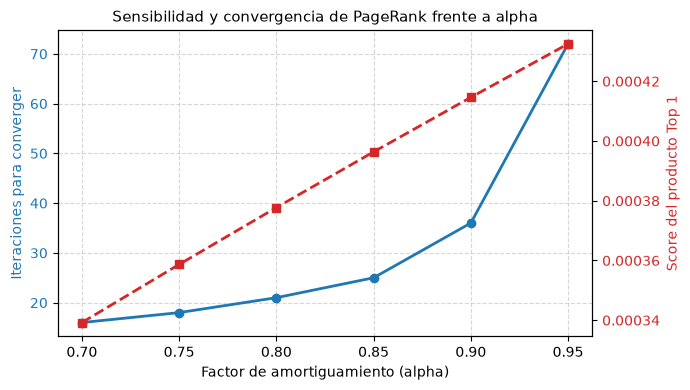

In [9]:
# 6.1 Grilla de Alpha en PageRank
tabla_alpha = pd.read_csv(R / "grilla_alpha.csv")
display(tabla_alpha[["alpha", "iteraciones", "convergido", "max_score", "std_score", "top1_asin"]])

fig, ax1 = plt.subplots(figsize=(7, 4))
color = "#1f77b4"
ax1.set_xlabel("Factor de amortiguamiento (alpha)", fontsize=10)
ax1.set_ylabel("Iteraciones para converger", color=color, fontsize=10)
ax1.plot(tabla_alpha["alpha"], tabla_alpha["iteraciones"], marker="o", color=color, linewidth=2)
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
color = "#d62728"
ax2.set_ylabel("Score del producto Top 1", color=color, fontsize=10)
ax2.plot(tabla_alpha["alpha"], tabla_alpha["top1_score"], marker="s", color=color, linewidth=2, linestyle="--")
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Sensibilidad y convergencia de PageRank frente a alpha", fontsize=11)
fig.tight_layout()
plt.show()


In [10]:
# 6.2 Grilla de Resolución de Louvain
tabla_res = pd.read_csv(R / "grilla_resolucion.csv")
display(tabla_res)


,resolucion,modularidad,n_comunidades,componentes_conexas,comunidades_por_componente,niveles,comunidad_max_nodos,comunidad_mediana_nodos
0,0.5,0.998960,841,841,1.0,3,356,282.0
1,1.0,0.997920,841,841,1.0,3,356,282.0
2,2.0,0.995841,841,841,1.0,3,356,282.0
3,5.0,0.989601,841,841,1.0,3,356,282.0
4,10.0,0.979203,841,841,1.0,3,356,282.0
5,20.0,0.958405,841,841,1.0,3,356,282.0


## Paso 7. Resultados en el pipeline e inspección cualitativa

Vinculamos los índices calculados con los metadatos reales del catálogo de productos (`AlmacenCatalogo` de la Etapa 3):
- Identificamos los **productos ancla** más influyentes según PageRank y Grado Ponderado.
- Inspeccionamos el significado semántico de las **comunidades** detectadas por Louvain (por ejemplo, cartuchos de tinta/tóner, papelería escolar, suministros de embalaje/envío).


In [11]:
# 7.1 Carga del catálogo
almacen = AlmacenCatalogo(RUTA_CATALOGO)

# Top 10 por PageRank
orden_pr = np.argsort(-pr_scores)[:10]
filas_pr = []
for idx in orden_pr:
    asin = grafo.asins[idx]
    reg = almacen.leer(asin) or {}
    precio = reg.get("precio")
    precio_str = f"${float(precio):.2f}" if precio is not None else "N/D"
    filas_pr.append({
        "ASIN": asin,
        "PageRank": f"{pr_scores[idx]:.6f}",
        "Grado_Pond": int(grados_ponderados[idx]),
        "Título": (reg.get("title") or "N/D")[:65],
        "Categoría": reg.get("categoria_hoja") or "N/D",
        "Precio": precio_str
    })

print("--- TOP 10 PRODUCTOS POR PAGERANK (CENTRALIDAD GLOBAL) ---")
display(pd.DataFrame(filas_pr))


--- TOP 10 PRODUCTOS POR PAGERANK (CENTRALIDAD GLOBAL) ---


,ASIN,PageRank,Grado_Pond,Título,Categoría,Precio
0,B0BF98LWMZ,0.000396,1420,TN436 ColorKing Compatible Toner Cartridge Rep...,Toner Cartridges,$62.99
1,B0BN478RWJ,0.000392,1606,HP DeskJet 2755e Wireless Color All-in-One Pri...,Inkjet Printers,$59.99
2,B087S2JRXY,0.000340,1424,"Amazon Basics 15-Sheet Cross-Cut Paper, CD Cre...",Shredders,$131.99
3,B0B3MX7LVG,0.000337,1471,"EZlifego Double Sided Tape Heavy Duty, Extra L...",Mounting Tape,$10.99
4,B0BZ67T58M,0.000330,1391,Office Chair Wheels Replacement Rubber Chair c...,Casters,$39.99
5,B09X5RYD9R,0.000295,751,DIVERSEBEE Bible Highlighters and Pens No Blee...,Highlighters,$9.95
6,B0C36Q7PM4,0.000294,1052,"Amazon Basics Multipurpose Copy Printer Paper,...",Copy & Multipurpose Paper,$8.49
7,B09PWTVGPW,0.000293,1071,"Alientape Nano Double Sided Tape, Multipurpose...",Mounting Tape,$17.95
8,B07GNNGXNK,0.000289,920,"Gorilla Grip Desk Chair Mat, No Divots, Rollin...",Carpet Chair Mats,N/D
9,B082F417S1,0.000252,891,"Leather Desk Pad Protector,Mouse Pad,Office De...",Mouse Pads,$11.89


In [12]:
# 7.2 Inspección de Clústeres Semánticos de Louvain
top_comunidades = conteo_louvain.head(4).index

for c_id in top_comunidades:
    nodos_c = np.where(comunidades_louvain == c_id)[0]
    # Tomar los de mayor PageRank dentro del clúster
    nodos_c_top = nodos_c[np.argsort(-pr_scores[nodos_c])[:4]]
    print(f"\n=== COMUNIDAD {c_id} (Total miembros: {len(nodos_c):,} productos) ===")
    for idx in nodos_c_top:
        asin = grafo.asins[idx]
        reg = almacen.leer(asin) or {}
        print(f"  [{asin}] ({reg.get('categoria_hoja')}) {(reg.get('title') or '')[:70]}...")

almacen.cerrar()



=== COMUNIDAD 616 (Total miembros: 356 productos) ===
  [B0B3MX7LVG] (Mounting Tape) EZlifego Double Sided Tape Heavy Duty, Extra Large Nano Double Sided A...
  [B09Y8HDMV7] (Desktop Photo Printers) KODAK Dock Plus 4PASS Instant Photo Printer (4x6 inches) + 90 Sheets B...
  [B079PG2BT6] (Laser & Inkjet Printer Labels) Blank White Permanent Adhesive Labels for Laser/Ink Jet Printer (4" x ...
  [B0BVWCML3V] (Ink Tank Printers) Epson EcoTank ET-4850 Wireless All-in-One Cartridge-Free Supertank Pri...

=== COMUNIDAD 251 (Total miembros: 352 productos) ===
  [B07XY35M94] (Pencil Holders) EASTHILL Big Capacity Pencil Pen Case Office College School Large Stor...
  [B0C1KN5CP7] (Lap Desks) HUANUO Adjustable Lap Desk - with 8 Adjustable Angles & Dual Cushions ...
  [B0CBNFP2R5] (Label Printers) Nelko Bluetooth Thermal Shipping Label Printer, Wireless 4x6 for Small...
  [B082Y7DFVC] (Calligraphy Pens) VANGOAL Feather Pen and Ink Set, Glittering Quill Pen Set Antique Call...

=== COMUNIDAD 145 (

## Paso 8. Salidas de la etapa 8

Verificamos la persistencia de los artefactos generados según el contrato de interfaces:
1. `grafo_cocompra.npz`: Matriz dispersa CSR del grafo.
2. `pagerank.parquet`: Puntuaciones de PageRank y Grado Ponderado.
3. `comunidades.parquet`: Asignación de comunidad Louvain y LPA.
4. `metricas.json`: Métricas de convergencia, tiempos y memoria.


In [13]:
for ruta in (RUTA_GRAFO, RUTA_PAGERANK, RUTA_COMUNIDADES, RUTA_METRICAS):
    tam_mb = ruta.stat().st_size / (1024 * 1024)
    print(f"✓ {ruta.name:25s} | Tamaño: {tam_mb:7.2f} MB ({ruta.stat().st_size:,} bytes)")

metricas = json.loads(RUTA_METRICAS.read_text(encoding="utf-8"))
print("\nResumen de Métricas JSON:")
print(json.dumps(metricas, indent=2))


✓ grafo_cocompra.npz        | Tamaño:    5.80 MB (6,081,098 bytes)
✓ pagerank.parquet          | Tamaño:    4.76 MB (4,995,089 bytes)
✓ comunidades.parquet       | Tamaño:    1.82 MB (1,909,904 bytes)
✓ metricas.json             | Tamaño:    0.00 MB (1,249 bytes)

Resumen de Métricas JSON:
{
  "grafo": {
    "nodos": 150534,
    "aristas": 805587,
    "peso_total": 1067474.0,
    "densidad": 7.110106831501846e-05,
    "min_peso": 1,
    "compras_procesadas": 1978936,
    "compras_bloqueadas_excluidas": 31878,
    "ordenes_legitimas": 1303414,
    "ordenes_con_cocompra": 324550,
    "segundos_extraccion": 27.357018208000227,
    "memoria_csr_bytes": 20538368
  },
  "pagerank": {
    "alpha": 0.85,
    "tol": 1e-06,
    "iteraciones": 25,
    "convergido": true,
    "segundos_pagerank": 0.20510724999621743,
    "segundos_grado": 6.054199911886826e-05,
    "top1_asin": "B0BF98LWMZ",
    "top1_score": 0.00039635901684100916
  },
  "comunidades": {
    "resolucion": 1.0,
    "componentes_co

## Paso 9. Experimentos de escalabilidad y comparación con NetworkX

Comparamos la eficiencia computacional y el uso de memoria de nuestras estructuras CSR vectorizadas frente a la biblioteca de referencia **NetworkX**:
- Subgrafos inducidos escalonados: $n \in \{1\,000, 10\,000, 50\,000, 100\,000, 150\,534\}$.
- Comparación de tiempos de ejecución y speedup.
- Análisis de complejidad empírica y extrapolación a 10 millones de nodos.


In [14]:
# 9.1 Carga de tablas de escala
escala_pr = pd.read_csv(R / "escala_pagerank.csv")
escala_com = pd.read_csv(R / "escala_comunidades.csv")
ref_nx = pd.read_csv(R / "referencia_networkx.csv")

print("--- ESCALA PAGERANK ---")
display(escala_pr)

print("--- ESCALA COMUNIDADES (LOUVAIN vs LPA) ---")
display(escala_com)

print("--- COMPARACIÓN CON NETWORKX ---")
display(ref_nx)


--- ESCALA PAGERANK ---


,n,aristas,ms_pagerank,ms_grado,mem_actual_pr_bytes,mem_pico_pr_bytes,mem_actual_grado_bytes,mem_pico_grado_bytes
0,1235,7059,2.227167,0.005958,10352,400739,9976,20080
1,10222,55884,11.751833,0.008625,82096,2372166,81872,163872
2,50127,269450,67.933084,0.025333,401336,11480863,401112,802352
3,100225,537698,125.849208,0.048292,802104,22920385,801896,1603920
4,150534,805587,206.815333,0.064083,1204592,34360446,1204368,2408864


--- ESCALA COMUNIDADES (LOUVAIN vs LPA) ---


,n,aristas,segundos_louvain,modularidad_louvain,comunidades_louvain,niveles_louvain,mem_actual_louvain_bytes,mem_pico_louvain_bytes,segundos_lpa,modularidad_lpa,comunidades_lpa,iteraciones_lpa,mem_actual_lpa_bytes,mem_pico_lpa_bytes
0,1235,7059,0.389458,0.743634,6,3,14179,1523050,0.150135,0.742137,19,5,9165,459344
1,10222,55884,4.648484,0.969223,48,3,44599,12651833,1.704137,0.967720,100,7,44633,3407597
2,50127,269450,21.533661,0.993733,276,4,204958,62629410,7.264171,0.991620,577,6,204031,16429729
3,100225,537698,70.980682,0.996867,562,3,404992,125112960,19.762351,0.994741,1156,8,404474,32785928
4,150534,805587,87.933859,0.997920,841,3,606177,184911629,41.254268,0.995856,1712,11,605710,49129871


--- COMPARACIÓN CON NETWORKX ---


,n,aristas,ms_pagerank_propio,ms_pagerank_nx,speedup_pagerank,segundos_louvain_propio,segundos_louvain_nx,speedup_louvain,modularidad_propia,modularidad_nx,comunidades_propia,comunidades_nx
0,1235,7059,2.227167,4.091958,1.837293,0.389458,0.025846,0.066364,0.743634,0.743634,6,6
1,10222,55884,11.751833,30.013250,2.553921,4.648484,0.250603,0.053911,0.969223,0.969223,48,48


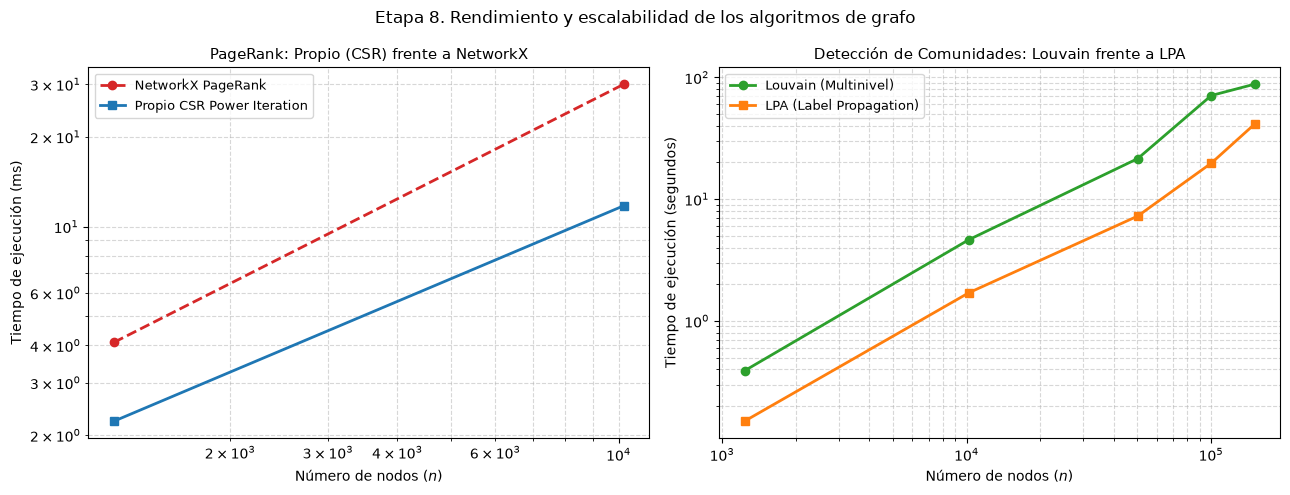

In [15]:
# 9.2 Gráficas comparativas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# PageRank Speedup vs NetworkX
axes[0].plot(ref_nx["n"], ref_nx["ms_pagerank_nx"], "o--", label="NetworkX PageRank", color="#d62728", linewidth=2)
axes[0].plot(ref_nx["n"], ref_nx["ms_pagerank_propio"], "s-", label="Propio CSR Power Iteration", color="#1f77b4", linewidth=2)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("PageRank: Propio (CSR) frente a NetworkX", fontsize=11)
axes[0].set_xlabel("Número de nodos ($n$)", fontsize=10)
axes[0].set_ylabel("Tiempo de ejecución (ms)", fontsize=10)
axes[0].grid(True, which="both", linestyle="--", alpha=0.5)
axes[0].legend(fontsize=9)

# Louvain vs LPA Tiempo
axes[1].plot(escala_com["n"], escala_com["segundos_louvain"], "o-", label="Louvain (Multinivel)", color="#2ca02c", linewidth=2)
axes[1].plot(escala_com["n"], escala_com["segundos_lpa"], "s-", label="LPA (Label Propagation)", color="#ff7f0e", linewidth=2)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Detección de Comunidades: Louvain frente a LPA", fontsize=11)
axes[1].set_xlabel("Número de nodos ($n$)", fontsize=10)
axes[1].set_ylabel("Tiempo de ejecución (segundos)", fontsize=10)
axes[1].grid(True, which="both", linestyle="--", alpha=0.5)
axes[1].legend(fontsize=9)

fig.suptitle("Etapa 8. Rendimiento y escalabilidad de los algoritmos de grafo", fontsize=12)
fig.tight_layout()
plt.show()


In [16]:
# 9.3 Extrapolación a 10M nodos
# Ajuste log-log: log(T) = a * log(n) + b  =>  T = exp(b) * n^a
def extrapolar(n_vals, t_vals, n_target=10_000_000):
    log_n = np.log(n_vals)
    log_t = np.log(t_vals)
    p = np.polyfit(log_n, log_t, deg=1)
    t_pred = np.exp(p[1]) * (n_target ** p[0])
    return p[0], t_pred

alpha_pr, t_10m_pr = extrapolar(escala_pr["n"].values, escala_pr["ms_pagerank"].values / 1000.0)
alpha_louv, t_10m_louv = extrapolar(escala_com["n"].values, escala_com["segundos_louvain"].values)
alpha_lpa, t_10m_lpa = extrapolar(escala_com["n"].values, escala_com["segundos_lpa"].values)

print(f"Extrapolación a 10 Millones de Nodos:")
print(f"  PageRank: Pendiente log-log a = {alpha_pr:.2f} | Tiempo proyectado: {t_10m_pr:.1f} s ({t_10m_pr/60:.2f} min)")
print(f"  Louvain:  Pendiente log-log a = {alpha_louv:.2f} | Tiempo proyectado: {t_10m_louv:.1f} s ({t_10m_louv/3600:.2f} horas)")
print(f"  LPA:      Pendiente log-log a = {alpha_lpa:.2f} | Tiempo proyectado: {t_10m_lpa:.1f} s ({t_10m_lpa/60:.2f} min)")


Extrapolación a 10 Millones de Nodos:
  PageRank: Pendiente log-log a = 0.95 | Tiempo proyectado: 10.1 s (0.17 min)
  Louvain:  Pendiente log-log a = 1.14 | Tiempo proyectado: 10941.4 s (3.04 horas)
  LPA:      Pendiente log-log a = 1.13 | Tiempo proyectado: 3740.6 s (62.34 min)


## Paso 9. Auditoría técnica (2026-10-27)

Verificaciones añadidas tras la auditoría de las etapas 8 y 9 (detalle en `docs/auditoria_etapas_8_9.md`):
1. **Conexión de comunidades (Louvain vs Leiden).** Se cuentan las comunidades internamente desconectadas y se parten en sus componentes con `dividir_comunidades_desconectadas`, en $O(|V| + |E|)$ y sin bajar $Q$.
2. **Comunidades frente a componentes conexas.** Si la partición coincide con las componentes, Louvain no aporta estructura más allá de un BFS.
3. **Pureza temática.** Fracción de productos cuya `categoria_hoja` es la mayoritaria de su comunidad, frente a la misma partición con etiquetas permutadas al azar.
4. **PageRank frente al grado.** En un grafo no dirigido el estado estacionario sin teletransporte es $k_i / 2m$; se mide cuánto se separa PageRank del grado.


In [17]:
# 9.1 Conexión de comunidades y contraste con componentes conexas
from scipy.stats import spearmanr

grafo_a = GrafoCoCompra.cargar_npz(RUTA_GRAFO)
com_a = pd.read_parquet(RUTA_COMUNIDADES)
n_cc, etiquetas_cc = componentes_conexas(grafo_a)
filas_aud = []
for col in ("comunidad_louvain", "comunidad_lpa"):
    particion = com_a[col].to_numpy()
    _, n_desconectadas = dividir_comunidades_desconectadas(grafo_a, particion)
    pares = np.unique(np.stack([particion, etiquetas_cc], axis=1), axis=0)
    filas_aud.append({
        "particion": col,
        "comunidades": len(np.unique(particion)),
        "componentes_conexas": n_cc,
        "comunidades_desconectadas": n_desconectadas,
        "igual_a_componentes": len(pares) == n_cc == len(np.unique(particion)),
        "modularidad": modularidad(grafo_a, particion),
    })
display(pd.DataFrame(filas_aud))
print(f"Q de la partición por componentes conexas: {modularidad(grafo_a, etiquetas_cc):.6f}")


,particion,comunidades,componentes_conexas,comunidades_desconectadas,igual_a_componentes,modularidad
0,comunidad_louvain,841,841,0,True,0.997920
1,comunidad_lpa,1712,841,0,False,0.995856


Q de la partición por componentes conexas: 0.997920


In [18]:
# 9.2 Pureza temática de las comunidades frente al azar
categoria_por_asin = {}
with open(RUTA_CATALOGO, encoding="utf-8") as f:
    for linea in f:
        prod = json.loads(linea)
        categoria_por_asin[prod["parent_asin"]] = prod.get("categoria_hoja")
com_a["categoria"] = com_a["parent_asin"].map(categoria_por_asin)


def pureza(df, col):
    g = df.dropna(subset=["categoria"]).groupby(col)["categoria"]
    return g.agg(lambda s: s.value_counts().iloc[0]).sum() / g.size().sum()


rng_a = np.random.default_rng(SEED)
permutada = com_a.assign(comunidad_louvain=rng_a.permutation(com_a["comunidad_louvain"].to_numpy()))
print(f"Pureza Louvain:            {pureza(com_a, 'comunidad_louvain'):.4f}")
print(f"Pureza con etiquetas azar: {pureza(permutada, 'comunidad_louvain'):.4f}")

# 9.3 PageRank frente al grado ponderado
pr_a = pd.read_parquet(RUTA_PAGERANK)
rho = spearmanr(pr_a["pagerank_score"], pr_a["grado_ponderado"]).correlation
top_pr = set(pr_a.nlargest(100, "pagerank_score")["parent_asin"])
top_gr = set(pr_a.nlargest(100, "grado_ponderado")["parent_asin"])
print(f"Spearman(PageRank, grado ponderado) = {rho:.4f}; coincidencia Top-100 = {len(top_pr & top_gr)}")


Pureza Louvain:            0.0672
Pureza con etiquetas azar: 0.0674
Spearman(PageRank, grado ponderado) = 0.9565; coincidencia Top-100 = 84


## Resumen de la etapa 8

| Tarea / Algoritmo | Línea Base | Complejidad Teórica | Resultado Principal en Datos Reales |
| --- | --- | --- | --- |
| **Grafo Co-Compra** | Lista de adyacencia Python | $O(\|V\| + \|E\|)$ en CSR | 150 534 productos, 805 587 aristas, 5.8 MB en disco, 0 envenenamientos de fraude |
| **PageRank** | Grado Ponderado | $O(\|V\| + \|E\|)$ por iteración (SpMV) | Converge en 25 iteraciones en 207 ms; 1.8-2.6× más rápido que NetworkX (el «60×» previo era el calentamiento de la primera llamada); Spearman 0.956 con el grado ponderado |
| **Louvain** | Label Propagation (LPA) | $O(\|V\| \log \|V\|)$ empírico | $Q = 0.9979$, 841 comunidades = exactamente las 841 componentes conexas para todo $\gamma \in [0.5, 20]$; pureza de categoría 0.067, igual al azar (0.067) |
| **LPA** | Inicialización trivial | $O(k \cdot \|E\|)$ cuasi-lineal | $Q = 0.9959$ en 11 iteraciones; 6 comunidades desconectadas partidas en sus componentes (1 712 comunidades) |

## Referencias

- **Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008).** Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment*, 2008(10), P10008.
- **Brin, S., & Page, L. (1998).** The anatomy of a large-scale hypertextual Web search engine. *Computer Networks and ISDN Systems*, 30(1-7), 107-117.
- **Newman, M. E. J. (2004).** Fast algorithm for detecting community structure in networks. *Physical Review E*, 69(6), 066133.
- **Newman, M. E. J. (2006).** Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577-8582.
- **Raghavan, U. N., Albert, R., & Kumara, S. (2007).** Near linear time algorithm to detect community structures in large-scale networks. *Physical Review E*, 76(3), 036106.
- **Hagberg, A., Swart, P., & S Chult, D. (2008).** Exploring network structure, dynamics, and function using NetworkX. *Proceedings of the 7th Python in Science Conference (SciPy 2008)*.
